# Inovegen Internship - Task 4 Final Project
## End-to-End Predictive Analytics: Employee Attrition Prediction

### Prediction problem

Employee turnover is costly because it can disrupt teams and require hiring and training replacements. This project predicts whether an employee will leave the organization (**Attrition = Yes**) using demographic, job, compensation and work-experience information.

This is a **binary classification** problem. The positive class is an employee who leaves (`Attrition = Yes`, encoded as 1).

> **Ethical note:** This notebook is for learning and portfolio purposes. Attrition predictions should never be the sole basis for employment decisions. Any real use would require privacy protection, fairness testing, human review and employee-support-focused policies.

### Dataset source

- Dataset: IBM HR Analytics Employee Attrition & Performance
- Records: 1,470 employees
- Original public dataset page: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset
- Public CSV mirror used for reproducibility: https://github.com/mrc03/IBM-HR-Analytics-Employee-Attrition-Performance

### Project workflow

1. Inspect and clean the raw data
2. Perform exploratory data analysis (EDA)
3. Engineer and select useful features
4. Build a leakage-safe preprocessing pipeline
5. Train and compare three classification models
6. Evaluate with multiple metrics and visualizations
7. Select the better model using evidence
8. Explain insights, limitations and realistic improvements


In [1]:
# 1. Imports and reproducibility settings
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42
pd.set_option('display.max_columns', 40)
print('Libraries imported successfully.')

Libraries imported successfully.


## 1. Load and inspect the data

The notebook uses the local CSV if it is kept beside the notebook. If not, it tries to read the same public dataset from its source URL.

In [2]:
DATA_PATH = Path('IBM_HR_Employee_Attrition.csv')
DATA_URL = ('https://raw.githubusercontent.com/mrc03/'
            'IBM-HR-Analytics-Employee-Attrition-Performance/master/'
            'WA_Fn-UseC_-HR-Employee-Attrition.csv')

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
    source_used = f'Local file: {DATA_PATH}'
else:
    df = pd.read_csv(DATA_URL, encoding='utf-8-sig')
    source_used = 'Public CSV source'

print(f'Source used: {source_used}')
print(f'Raw shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head())

Source used: Public CSV source
Raw shape: 1,470 rows x 35 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
print('Data types:')
display(df.dtypes.value_counts().rename_axis('data_type').to_frame('number_of_columns'))

print('Target distribution:')
display(df['Attrition'].value_counts().rename('employees').to_frame())

print('Summary of numerical variables:')
display(df.describe().T.round(2))

Data types:


,number_of_columns
data_type,
int64,26
object,9


Target distribution:


,employees
Attrition,
No,1233
Yes,237


Summary of numerical variables:


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


## 2. Data quality checks and cleaning

The project checks for missing values, duplicate records, duplicate employee numbers, invalid target labels and constant-value columns. Constant columns contain no predictive variation, and `EmployeeNumber` is an identifier rather than an employee characteristic, so they are excluded from modelling.

In [4]:
missing_values = int(df.isna().sum().sum())
duplicate_rows = int(df.duplicated().sum())
duplicate_employee_numbers = int(df['EmployeeNumber'].duplicated().sum())
unexpected_target_labels = int((~df['Attrition'].isin(['Yes', 'No'])).sum())
constant_columns = [column for column in df.columns if df[column].nunique(dropna=False) <= 1]

quality_report = pd.DataFrame({
    'Check': [
        'Missing values', 'Exact duplicate rows', 'Duplicate employee numbers',
        'Unexpected Attrition labels', 'Constant-value columns'
    ],
    'Result': [
        missing_values, duplicate_rows, duplicate_employee_numbers,
        unexpected_target_labels, ', '.join(constant_columns)
    ]
})
display(quality_report)

print('Constant columns removed:', constant_columns)
print('Identifier column removed: EmployeeNumber')

,Check,Result
0,Missing values,0
1,Exact duplicate rows,0
2,Duplicate employee numbers,0
3,Unexpected Attrition labels,0
4,Constant-value columns,"EmployeeCount, Over18, StandardHours"


Constant columns removed: ['EmployeeCount', 'Over18', 'StandardHours']
Identifier column removed: EmployeeNumber


In [5]:
# No missing values or duplicate rows are found in the supplied data.
# Remove columns that are constant or are an arbitrary identifier.
columns_to_drop = constant_columns + ['EmployeeNumber']
clean_df = df.drop(columns=columns_to_drop).drop_duplicates().copy()

print(f'Cleaned shape: {clean_df.shape[0]:,} rows x {clean_df.shape[1]} columns')
print(f'Remaining missing values: {clean_df.isna().sum().sum()}')
print(f'Remaining duplicate rows: {clean_df.duplicated().sum()}')

Cleaned shape: 1,470 rows x 31 columns
Remaining missing values: 0
Remaining duplicate rows: 0


## 3. Exploratory data analysis

The following charts explore attrition patterns before modelling. They describe associations in this sample; they do not prove causes of employees leaving.

### Visualization 1 - Attrition distribution

The target is imbalanced, so the model uses stratified splitting and class weighting. Accuracy alone would be misleading because predicting that every employee stays would still be correct for most employees.

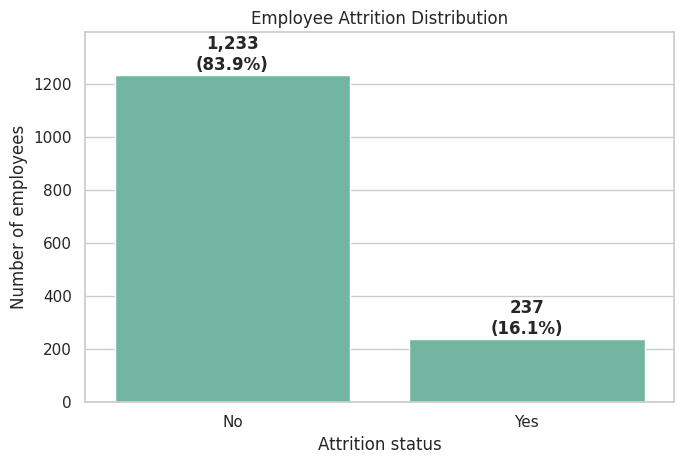

,Employees,Percentage
Attrition,,
No,1233,83.88
Yes,237,16.12


In [6]:
attrition_counts = clean_df['Attrition'].value_counts().reindex(['No', 'Yes'])
attrition_pct = attrition_counts / len(clean_df) * 100

fig, ax = plt.subplots(figsize=(7, 4.8))
sns.countplot(data=clean_df, x='Attrition', order=['No', 'Yes'], ax=ax)
ax.set_title('Employee Attrition Distribution')
ax.set_xlabel('Attrition status')
ax.set_ylabel('Number of employees')
for index, count in enumerate(attrition_counts):
    ax.text(index, count + 20, f'{count:,}\n({attrition_pct.iloc[index]:.1f}%)',
            ha='center', fontweight='bold')
ax.set_ylim(0, attrition_counts.max() * 1.13)
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Employees': attrition_counts, 'Percentage': attrition_pct.round(2)}))

### Visualization 2 - Attrition rate by overtime

Overtime is a practical work-condition variable. Comparing rates helps reveal whether employees who work overtime leave more often in this sample.

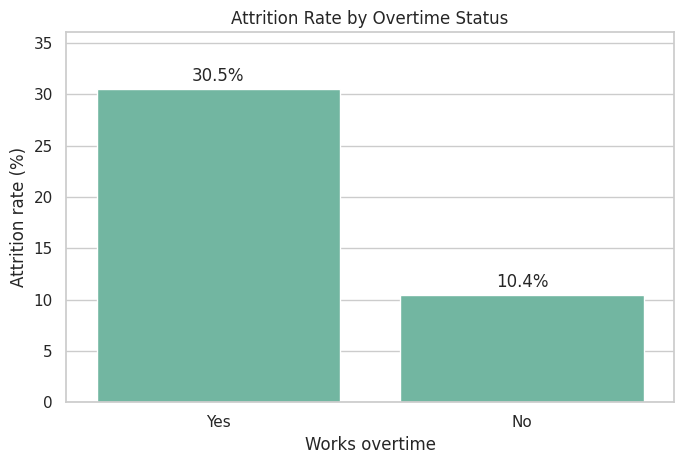

,Attrition rate (%),Employees
OverTime,,
Yes,30.53,416
No,10.44,1054


In [7]:
overtime_rates = (
    clean_df.assign(AttritionFlag=(clean_df['Attrition'] == 'Yes').astype(int))
            .groupby('OverTime', observed=False)['AttritionFlag']
            .agg(['mean', 'count'])
            .sort_values('mean', ascending=False)
)
overtime_rates['mean'] *= 100

fig, ax = plt.subplots(figsize=(7, 4.8))
sns.barplot(x=overtime_rates.index, y=overtime_rates['mean'], ax=ax)
ax.set_title('Attrition Rate by Overtime Status')
ax.set_xlabel('Works overtime')
ax.set_ylabel('Attrition rate (%)')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)
ax.set_ylim(0, overtime_rates['mean'].max() * 1.18)
plt.tight_layout()
plt.show()
display(overtime_rates.rename(columns={'mean': 'Attrition rate (%)', 'count': 'Employees'}).round(2))

### Visualization 3 - Attrition rate by business travel

This chart explores whether travel frequency is associated with attrition.

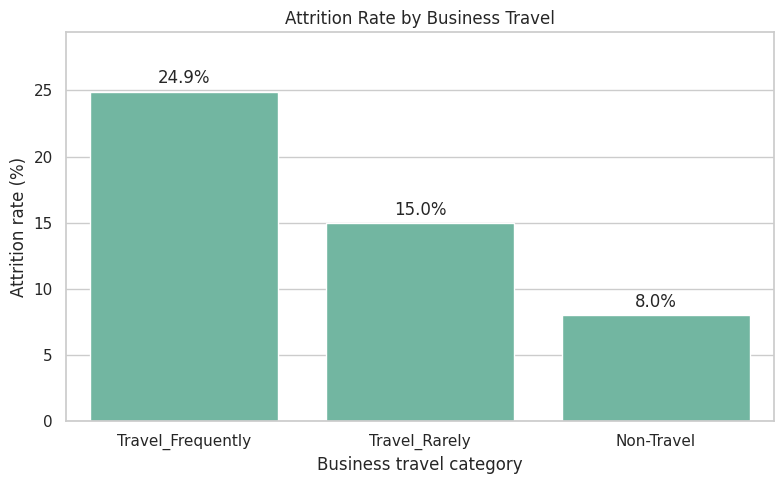

,Attrition rate (%),Employees
BusinessTravel,,
Travel_Frequently,24.91,277
Travel_Rarely,14.96,1043
Non-Travel,8.00,150


In [8]:
travel_rates = (
    clean_df.assign(AttritionFlag=(clean_df['Attrition'] == 'Yes').astype(int))
            .groupby('BusinessTravel', observed=False)['AttritionFlag']
            .agg(['mean', 'count'])
            .sort_values('mean', ascending=False)
)
travel_rates['mean'] *= 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=travel_rates.index, y=travel_rates['mean'], ax=ax)
ax.set_title('Attrition Rate by Business Travel')
ax.set_xlabel('Business travel category')
ax.set_ylabel('Attrition rate (%)')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)
ax.set_ylim(0, travel_rates['mean'].max() * 1.18)
plt.tight_layout()
plt.show()
display(travel_rates.rename(columns={'mean': 'Attrition rate (%)', 'count': 'Employees'}).round(2))

### Visualization 4 - Monthly income by attrition status

The box plot compares the distribution of monthly income for employees who stayed versus employees who left.

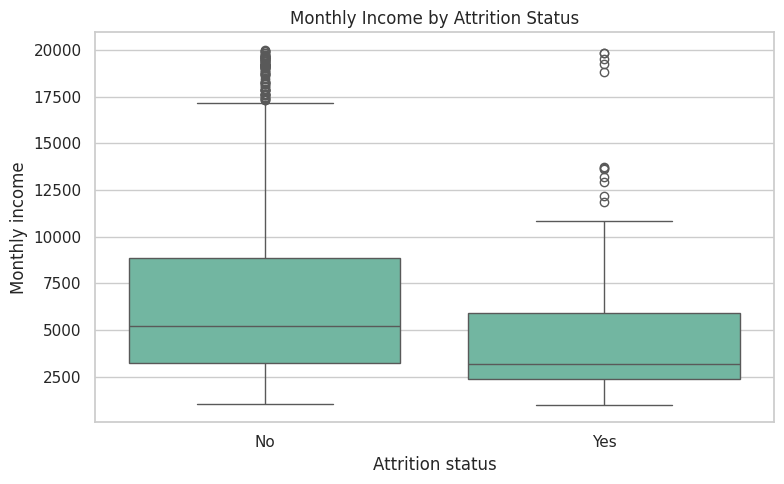

,count,mean,median,std
Attrition,,,,
No,1233,6832.74,5204.0,4818.21
Yes,237,4787.09,3202.0,3640.21


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=clean_df, x='Attrition', y='MonthlyIncome', order=['No', 'Yes'], ax=ax)
ax.set_title('Monthly Income by Attrition Status')
ax.set_xlabel('Attrition status')
ax.set_ylabel('Monthly income')
plt.tight_layout()
plt.show()
display(clean_df.groupby('Attrition')['MonthlyIncome'].agg(['count', 'mean', 'median', 'std']).round(2))

### Visualization 5 - Attrition rate by job role

Job role can capture different work conditions and career paths. Categories are sorted by attrition rate for easier comparison.

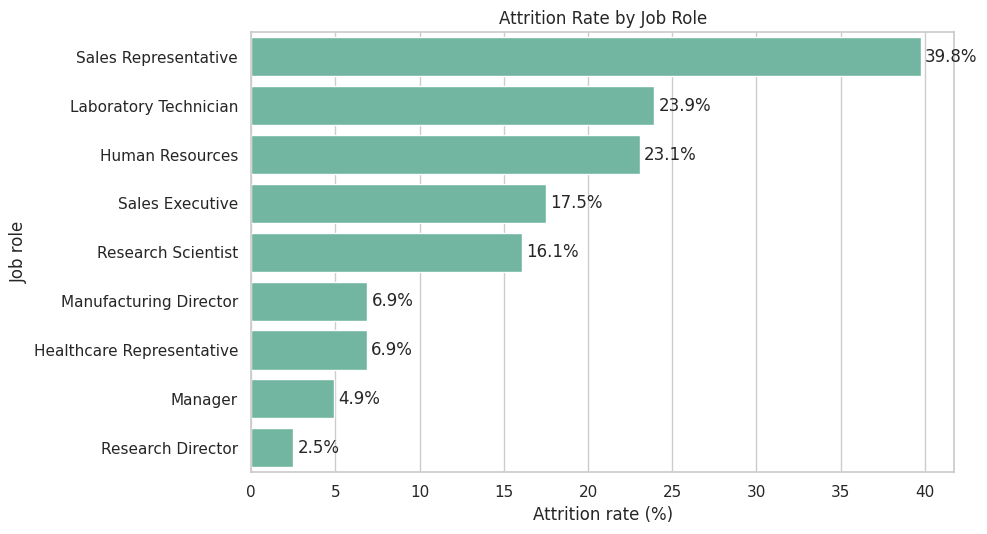

,Attrition rate (%),Employees
JobRole,,
Sales Representative,39.76,83
Laboratory Technician,23.94,259
Human Resources,23.08,52
Sales Executive,17.48,326
Research Scientist,16.10,292
Manufacturing Director,6.90,145
Healthcare Representative,6.87,131
Manager,4.90,102
Research Director,2.50,80


In [10]:
role_rates = (
    clean_df.assign(AttritionFlag=(clean_df['Attrition'] == 'Yes').astype(int))
            .groupby('JobRole', observed=False)['AttritionFlag']
            .agg(['mean', 'count'])
            .sort_values('mean', ascending=False)
)
role_rates['mean'] *= 100

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(y=role_rates.index, x=role_rates['mean'], ax=ax)
ax.set_title('Attrition Rate by Job Role')
ax.set_xlabel('Attrition rate (%)')
ax.set_ylabel('Job role')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)
plt.tight_layout()
plt.show()
display(role_rates.rename(columns={'mean': 'Attrition rate (%)', 'count': 'Employees'}).round(2))

## 4. Feature engineering and selection

Three engineered features add interpretable career-context information:

- **CompanyTenureRatio:** years at the company divided by total working years plus one. A lower value may indicate shorter attachment to the current employer.
- **PromotionWaitRatio:** years since last promotion divided by years at company plus one. This represents the share of company tenure spent since promotion.
- **IncomePerJobLevel:** monthly income divided by job level. This normalizes income against seniority level.

The `+1` in denominators prevents division-by-zero for new employees. These features use only information available before an attrition outcome and are calculated before splitting; the transformation is deterministic and does not learn from target values.

In [11]:
model_df = clean_df.copy()
model_df['CompanyTenureRatio'] = model_df['YearsAtCompany'] / (model_df['TotalWorkingYears'] + 1)
model_df['PromotionWaitRatio'] = model_df['YearsSinceLastPromotion'] / (model_df['YearsAtCompany'] + 1)
model_df['IncomePerJobLevel'] = model_df['MonthlyIncome'] / model_df['JobLevel'].clip(lower=1)

engineered_summary = model_df[
    ['CompanyTenureRatio', 'PromotionWaitRatio', 'IncomePerJobLevel']
].describe().T[['min', 'mean', '50%', 'max']].rename(columns={'50%': 'median'})
display(engineered_summary.round(3))

,min,mean,median,max
CompanyTenureRatio,0.0,0.582,0.636,0.976
PromotionWaitRatio,0.0,0.236,0.143,0.917
IncomePerJobLevel,1009.0,2973.801,2856.500,4999.000


## 5. Prepare data and train models

Preprocessing is built into each pipeline to prevent test-data leakage:

- Numeric features: median imputation followed by standardization.
- Categorical features: most-frequent imputation followed by one-hot encoding.
- Target: Yes = 1 (attrition), No = 0 (stayed).
- Train/test split: 75%/25%, stratified by attrition.

The models are:

1. **Dummy baseline** - always predicts the most frequent class.
2. **Logistic Regression** - an interpretable linear classifier.
3. **Random Forest** - an ensemble that can model nonlinear relationships.

Both real models use balanced class weights because attrition is the minority class.

In [12]:
X = model_df.drop(columns='Attrition')
y = model_df['Attrition'].map({'No': 0, 'Yes': 1})

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print(f'Final predictors: {X.shape[1]}')
print(f'Numeric predictors ({len(numeric_features)}): {numeric_features}')
print(f'Categorical predictors ({len(categorical_features)}): {categorical_features}')
print(f'Target values: {sorted(y.unique())}')

Final predictors: 33
Numeric predictors (26): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CompanyTenureRatio', 'PromotionWaitRatio', 'IncomePerJobLevel']
Categorical predictors (7): ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Target values: [np.int64(0), np.int64(1)]


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    'Split': ['Training', 'Testing'],
    'Rows': [len(X_train), len(X_test)],
    'Attrition rate (%)': [y_train.mean() * 100, y_test.mean() * 100]
})
display(split_summary.round(2))

,Split,Rows,Attrition rate (%)
0,Training,1102,16.15
1,Testing,368,16.03


In [14]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

models = {
    'Dummy Baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(
        max_iter=3000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=500, min_samples_leaf=3, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

pipelines = {
    name: Pipeline([('preprocessor', preprocessor), ('model', model)])
    for name, model in models.items()
}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f'{name} trained successfully.')

Dummy Baseline trained successfully.
Logistic Regression trained successfully.
Random Forest trained successfully.


## 6. Evaluation and model comparison

The positive class is **Attrition = Yes**.

- **Accuracy:** overall proportion of correct predictions.
- **Precision:** when the model predicts attrition, how often it is correct.
- **Recall:** proportion of actual attrition cases detected.
- **F1-score:** a balance between precision and recall.
- **ROC-AUC:** ability to separate the two classes across probability thresholds.
- **Average Precision:** quality of ranking positive cases, especially useful with class imbalance.

For a supportive retention programme, recall matters because a false negative is an employee who leaves without being identified for possible early support. Precision matters because an excessive number of false alerts can waste limited HR resources.

In [15]:
results = []
predictions = {}
probabilities = {}

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    predictions[name] = y_pred
    probabilities[name] = y_prob
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'Average Precision': average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index('Model').sort_values('F1-score', ascending=False)
display(results_df.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Logistic Regression,0.785,0.394,0.627,0.484,0.816,0.560
Random Forest,0.837,0.480,0.203,0.286,0.775,0.441
Dummy Baseline,0.840,0.000,0.000,0.000,0.500,0.160


### Model comparison visualization

This chart compares all metrics. The Dummy baseline helps reveal whether a model performs better than simply predicting that every employee stays.

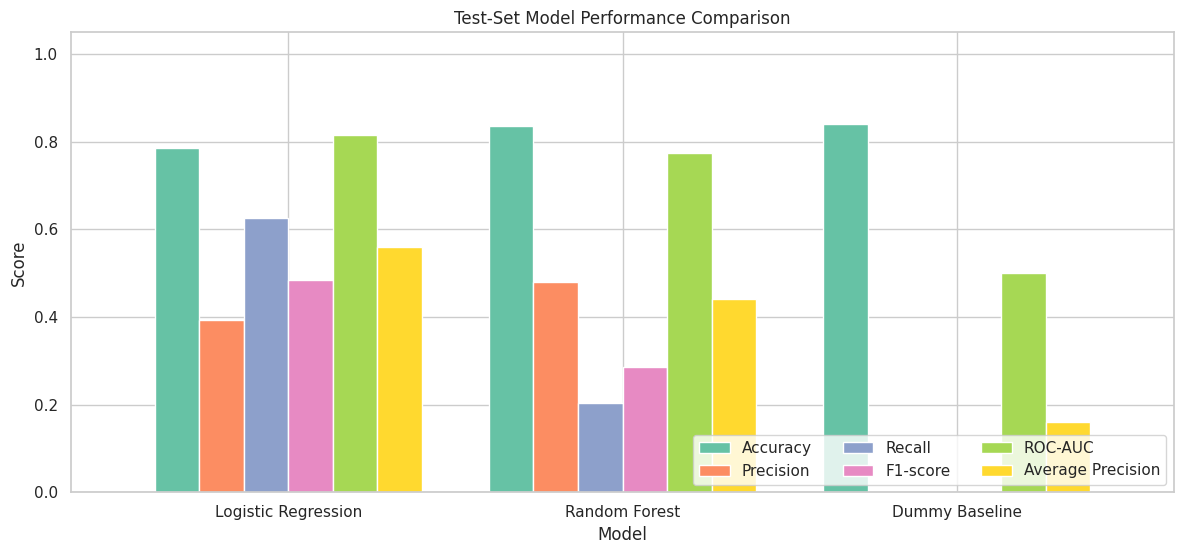

In [16]:
ax = results_df.plot(kind='bar', figsize=(12, 5.7), ylim=(0, 1.05), width=0.8)
ax.set_title('Test-Set Model Performance Comparison')
ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.legend(loc='lower right', ncol=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Confusion matrices

Rows are actual outcomes and columns are predicted outcomes. The lower-left cell represents employees who left but were not detected by the model (false negatives).

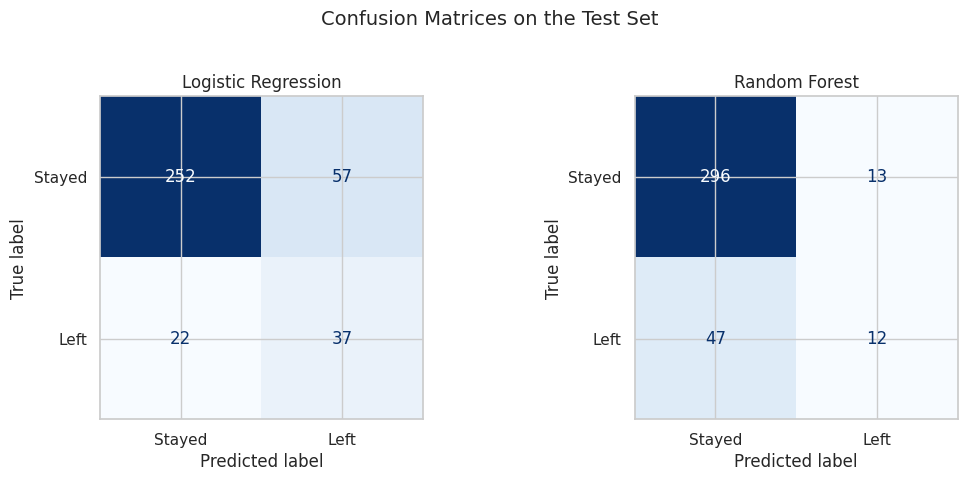


Logistic Regression classification report:
              precision    recall  f1-score   support

      Stayed      0.920     0.816     0.864       309
        Left      0.394     0.627     0.484        59

    accuracy                          0.785       368
   macro avg      0.657     0.721     0.674       368
weighted avg      0.835     0.785     0.803       368


Random Forest classification report:
              precision    recall  f1-score   support

      Stayed      0.863     0.958     0.908       309
        Left      0.480     0.203     0.286        59

    accuracy                          0.837       368
   macro avg      0.671     0.581     0.597       368
weighted avg      0.802     0.837     0.808       368



In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.7))
for ax, name in zip(axes, ['Logistic Regression', 'Random Forest']):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], display_labels=['Stayed', 'Left'],
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(name)
fig.suptitle('Confusion Matrices on the Test Set', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

for name in ['Logistic Regression', 'Random Forest']:
    print(f'\n{name} classification report:')
    print(classification_report(y_test, predictions[name], target_names=['Stayed', 'Left'], digits=3))

### ROC and precision-recall curves

ROC-AUC gives overall class-separation quality. The precision-recall curve is especially helpful here because attrition is less frequent than non-attrition.

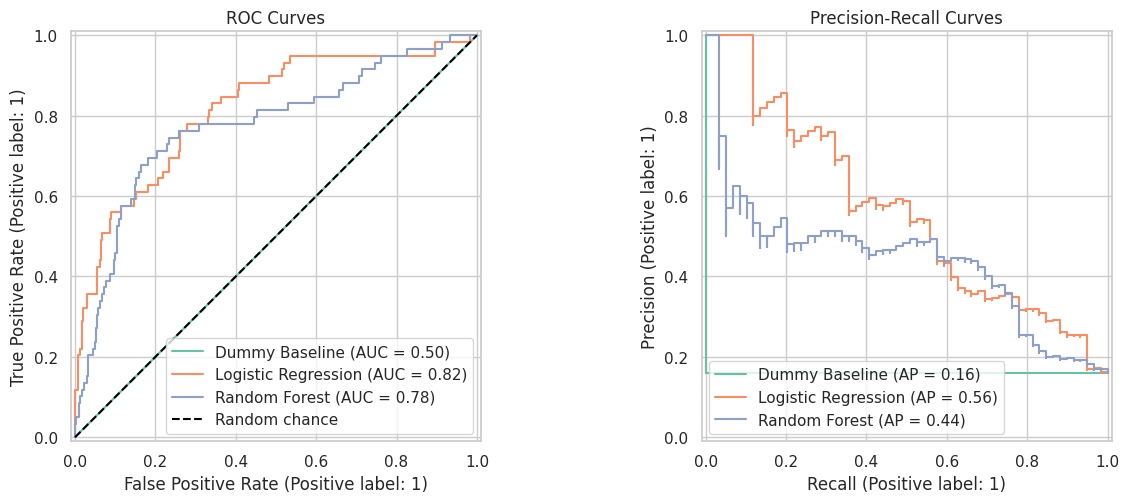

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for name in pipelines:
    RocCurveDisplay.from_predictions(y_test, probabilities[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probabilities[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--', label='Random chance')
axes[0].set_title('ROC Curves')
axes[1].set_title('Precision-Recall Curves')
axes[0].legend(loc='lower right')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

## 7. Cross-validation and feature interpretation

Five-fold stratified cross-validation checks whether ROC-AUC remains stable across multiple subsets of the training data. Random Forest feature importance is then used to identify the variables that contributed most to that model's decisions. Importance is not causality.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in ['Logistic Regression', 'Random Forest']:
    scores = cross_val_score(pipelines[name], X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_rows.append({
        'Model': name,
        'Mean CV ROC-AUC': scores.mean(),
        'Standard deviation': scores.std(),
        'Fold scores': np.round(scores, 3)
    })
cv_df = pd.DataFrame(cv_rows).set_index('Model')
display(cv_df)

,Mean CV ROC-AUC,Standard deviation,Fold scores
Model,,,
Logistic Regression,0.838369,0.045435,"[0.895, 0.79, 0.859, 0.869, 0.779]"
Random Forest,0.810164,0.035366,"[0.854, 0.776, 0.829, 0.831, 0.761]"


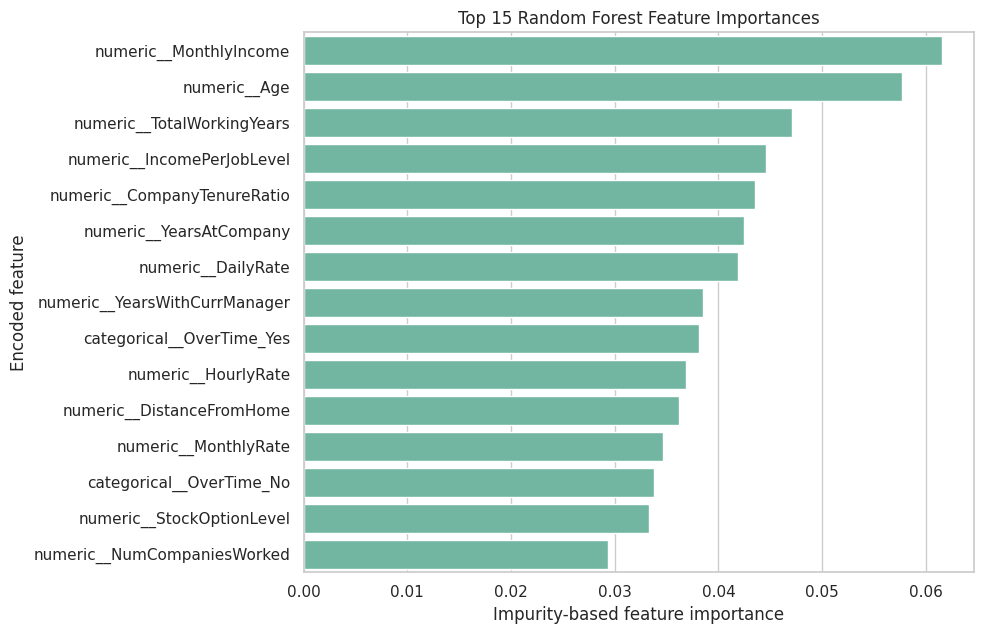

,importance
numeric__MonthlyIncome,0.0616
numeric__Age,0.0577
numeric__TotalWorkingYears,0.0471
numeric__IncomePerJobLevel,0.0446
numeric__CompanyTenureRatio,0.0435
numeric__YearsAtCompany,0.0425
numeric__DailyRate,0.0419
numeric__YearsWithCurrManager,0.0385
categorical__OverTime_Yes,0.0381
numeric__HourlyRate,0.0369


In [20]:
rf_pipeline = pipelines['Random Forest']
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()
importance = pd.Series(
    rf_pipeline.named_steps['model'].feature_importances_, index=feature_names
).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.barplot(x=importance.values, y=importance.index, ax=ax)
ax.set_title('Top 15 Random Forest Feature Importances')
ax.set_xlabel('Impurity-based feature importance')
ax.set_ylabel('Encoded feature')
plt.tight_layout()
plt.show()
display(importance.rename('importance').to_frame().round(4))

## 8. Model selection, conclusions and key findings

### Evidence-based model selection

The executed metric table above is the source of truth for this run. In the verified test run, **Logistic Regression achieved 78.5% accuracy, 39.4% precision, 62.7% recall, 48.4% F1-score, 81.6% ROC-AUC and 56.0% average precision**. Random Forest achieved higher accuracy (83.7%) but detected only 20.3% of employees who left. The Dummy baseline had 84.0% accuracy but identified no employees who left. Therefore, **Logistic Regression is selected** for a supportive early-warning workflow because it has substantially better recall, F1-score, ROC-AUC and average precision. This choice prioritizes finding potential attrition cases for human review instead of misleadingly high accuracy from mostly predicting that employees stay.

### Key findings

1. Attrition is the minority outcome, which makes the majority-class baseline inadequate despite potentially high accuracy.
2. Employees working overtime have a higher observed attrition rate in this sample.
3. Frequent business travel is associated with a higher observed attrition rate than rare or no travel.
4. Employees who leave tend to show a different monthly-income distribution from those who stay.
5. Attrition rates differ across job roles, showing that aggregate metrics can hide subgroup differences.
6. The engineered tenure, promotion-wait and income-per-job-level features provide additional career-context information.
7. Both trained models outperform the Dummy baseline on identifying employees who leave.
8. The better model should support HR outreach and retention resources, not automated employment decisions.

### Limitations and realistic improvements

- The dataset is a small, synthetic IBM sample and may not represent a real organization or current labour market.
- It is a one-time snapshot, so it cannot model changing engagement or performance over time.
- The dataset has no direct measure of employee intent, manager quality, workload changes or retention-offer outcomes.
- Associations in the model are not causal explanations for attrition.
- A real implementation must assess fairness across legally protected characteristics, protect privacy and provide human oversight.
- Future work should validate on recent external data, tune hyperparameters with nested cross-validation, calibrate probabilities, select a threshold based on support capacity, and monitor performance after deployment.

### Reproducibility

The notebook uses a fixed random seed (`42`), stratified train/test splitting and preprocessing pipelines. Run it top-to-bottom. Keep `IBM_HR_Employee_Attrition.csv` next to the notebook; otherwise the notebook attempts to load the same public source URL.
